In [1]:
import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [2]:
X_train = pd.DataFrame({
    "fico_n": [650.0, 700.0, 750.0, 800.0],
    "dti_n": [10.0, 20.0, np.nan, 40.0],
    "revenue": [40000.0, 50000.0, 60000.0, 90000.0],
    "loan_amnt": [5000.0, 10000.0, 15000.0, 20000.0],
})

X_train

,fico_n,dti_n,revenue,loan_amnt
0,650.0,10.0,40000.0,5000.0
1,700.0,20.0,50000.0,10000.0
2,750.0,NaN,60000.0,15000.0
3,800.0,40.0,90000.0,20000.0


In [3]:
imputer = SimpleImputer(strategy="median")

imputer.fit(X_train)

print("Learned medians:", imputer.statistics_)

Learned medians: [7.25e+02 2.00e+01 5.50e+04 1.25e+04]


In [4]:
X_imputed = imputer.transform(X_train)

pd.DataFrame(
    X_imputed,
    columns=X_train.columns,
)

,fico_n,dti_n,revenue,loan_amnt
0,650.0,10.0,40000.0,5000.0
1,700.0,20.0,50000.0,10000.0
2,750.0,20.0,60000.0,15000.0
3,800.0,40.0,90000.0,20000.0


In [5]:
X_validation = pd.DataFrame({
    "fico_n": [600.0, 620.0, np.nan],
    "dti_n": [50.0, np.nan, 70.0],
    "revenue": [150000.0, 200000.0, 250000.0],
    "loan_amnt": [25000.0, 30000.0, 35000.0],
})

X_validation

,fico_n,dti_n,revenue,loan_amnt
0,600.0,50.0,150000.0,25000.0
1,620.0,NaN,200000.0,30000.0
2,NaN,70.0,250000.0,35000.0


In [6]:
X_validation_imputed = pd.DataFrame(
    imputer.transform(X_validation),
    columns=X_validation.columns,
)

X_validation_imputed

,fico_n,dti_n,revenue,loan_amnt
0,600.0,50.0,150000.0,25000.0
1,620.0,20.0,200000.0,30000.0
2,725.0,70.0,250000.0,35000.0


In [7]:
wrong_imputer = SimpleImputer(strategy="median")

wrong_imputer.fit(X_validation)

print("Training medians:", imputer.statistics_)
print("Validation medians:", wrong_imputer.statistics_)

Training medians: [7.25e+02 2.00e+01 5.50e+04 1.25e+04]
Validation medians: [6.1e+02 6.0e+01 2.0e+05 3.0e+04]


In [8]:
scaler = StandardScaler()

scaler.fit(X_imputed)

print("Training means:", scaler.mean_)
print("Training standard deviations:", scaler.scale_)

Training means: [7.25e+02 2.25e+01 6.00e+04 1.25e+04]
Training standard deviations: [5.59016994e+01 1.08972474e+01 1.87082869e+04 5.59016994e+03]


In [9]:
X_train_scaled = scaler.transform(X_imputed)

X_validation_scaled = scaler.transform(X_validation_imputed.to_numpy())

print("Training data:")
display(pd.DataFrame(X_train_scaled, columns=X_train.columns))

print("Validation data:")
display(pd.DataFrame(X_validation_scaled, columns=X_validation.columns))

Training data:


,fico_n,dti_n,revenue,loan_amnt
0,-1.341641,-1.147079,-1.069045,-1.341641
1,-0.447214,-0.229416,-0.534522,-0.447214
2,0.447214,-0.229416,0.000000,0.447214
3,1.341641,1.605910,1.603567,1.341641


Validation data:


,fico_n,dti_n,revenue,loan_amnt
0,-2.236068,2.523573,4.810702,2.236068
1,-1.878297,-0.229416,7.483315,3.130495
2,0.000000,4.358899,10.155927,4.024922


In [10]:
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

X_train_processed = numerical_pipeline.fit_transform(X_train)

X_validation_processed = numerical_pipeline.transform(X_validation)

In [11]:
np.testing.assert_allclose(
    X_train_processed,
    X_train_scaled,
)

np.testing.assert_allclose(
    X_validation_processed,
    X_validation_scaled,
)

print("Pipeline reproduces both manual transformations.")

Pipeline reproduces both manual transformations.


In [12]:
from sklearn.preprocessing import OneHotEncoder

X_train_cat = pd.DataFrame({
    "home_ownership_n": [
        "RENT", "OWN", "MORTGAGE", "RENT"
    ],
    "purpose": [
        "debt_consolidation", "credit_card",
        "debt_consolidation", "small_business"
    ],
})

X_validation_cat = pd.DataFrame({
    "home_ownership_n": [
        "RENT", "OTHER"
    ],
    "purpose": [
        "credit_card", "debt_consolidation"
    ],
})

In [13]:
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False,
)

X_train_encoded = encoder.fit_transform(X_train_cat)

print("Learned categories:")
for feature, categories in zip(
    X_train_cat.columns,
    encoder.categories_,
):
    print(feature, categories)

print("\nEncoded training data:")

display(
    pd.DataFrame(
        X_train_encoded,
        columns=encoder.get_feature_names_out(),
    )
)

Learned categories:
home_ownership_n ['MORTGAGE' 'OWN' 'RENT']
purpose ['credit_card' 'debt_consolidation' 'small_business']

Encoded training data:


,home_ownership_n_MORTGAGE,home_ownership_n_OWN,home_ownership_n_RENT,purpose_credit_card,purpose_debt_consolidation,purpose_small_business
0,0.0,0.0,1.0,0.0,1.0,0.0
1,0.0,1.0,0.0,1.0,0.0,0.0
2,1.0,0.0,0.0,0.0,1.0,0.0
3,0.0,0.0,1.0,0.0,0.0,1.0


In [14]:
X_validation_encoded = encoder.transform(X_validation_cat)

display(
    pd.DataFrame(
        X_validation_encoded,
        columns=encoder.get_feature_names_out(),
    )
)

,home_ownership_n_MORTGAGE,home_ownership_n_OWN,home_ownership_n_RENT,purpose_credit_card,purpose_debt_consolidation,purpose_small_business
0,0.0,0.0,1.0,1.0,0.0,0.0
1,0.0,0.0,0.0,0.0,1.0,0.0


In [15]:
categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent"),
    ),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False,
        ),
    ),
])

In [16]:
X_train_cat_missing = X_train_cat.copy()

X_train_cat_missing.loc[1, "home_ownership_n"] = np.nan

X_train_cat_processed = categorical_pipeline.fit_transform(
    X_train_cat_missing
)

display(
    pd.DataFrame(
        X_train_cat_processed,
        columns=categorical_pipeline.get_feature_names_out(),
    )
)

,home_ownership_n_MORTGAGE,home_ownership_n_RENT,purpose_credit_card,purpose_debt_consolidation,purpose_small_business
0,0.0,1.0,0.0,1.0,0.0
1,0.0,1.0,1.0,0.0,0.0
2,1.0,0.0,0.0,1.0,0.0
3,0.0,1.0,0.0,0.0,1.0


In [17]:
imputer = categorical_pipeline.named_steps["imputer"]
encoder = categorical_pipeline.named_steps["encoder"]

print("Imputation values:")
print(imputer.statistics_)

print("\nCategories:")
print(encoder.categories_)

print("\nOutput features:")
print(categorical_pipeline.get_feature_names_out())

Imputation values:
['RENT' 'debt_consolidation']

Categories:
[array(['MORTGAGE', 'RENT'], dtype=object), array(['credit_card', 'debt_consolidation', 'small_business'],
      dtype=object)]

Output features:
['home_ownership_n_MORTGAGE' 'home_ownership_n_RENT' 'purpose_credit_card'
 'purpose_debt_consolidation' 'purpose_small_business']


In [18]:
X_train_full = X_train.copy()

X_train_full["home_ownership_n"] = [
    "RENT", "OWN", "MORTGAGE", "RENT"
]

X_train_full["purpose"] = [
    "debt_consolidation",
    "credit_card",
    "debt_consolidation",
    "small_business",
]

display(X_train_full)

,fico_n,dti_n,revenue,loan_amnt,home_ownership_n,purpose
0,650.0,10.0,40000.0,5000.0,RENT,debt_consolidation
1,700.0,20.0,50000.0,10000.0,OWN,credit_card
2,750.0,NaN,60000.0,15000.0,MORTGAGE,debt_consolidation
3,800.0,40.0,90000.0,20000.0,RENT,small_business


In [19]:
from sklearn.compose import ColumnTransformer

numerical_features = [
    "fico_n",
    "dti_n",
    "revenue",
    "loan_amnt",
]

categorical_features = [
    "home_ownership_n",
    "purpose",
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numerical_pipeline,
            numerical_features,
        ),
        (
            "cat",
            categorical_pipeline,
            categorical_features,
        ),
    ],
    remainder="drop",
    verbose_feature_names_out=True,
)

In [20]:
X_train_full_processed = preprocessor.fit_transform(
    X_train_full
)

feature_names = preprocessor.get_feature_names_out()

X_train_full_processed_df = pd.DataFrame(
    X_train_full_processed,
    columns=feature_names,
    index=X_train_full.index,
)

display(X_train_full_processed_df)

,num__fico_n,num__dti_n,num__revenue,num__loan_amnt,cat__home_ownership_n_MORTGAGE,cat__home_ownership_n_OWN,cat__home_ownership_n_RENT,cat__purpose_credit_card,cat__purpose_debt_consolidation,cat__purpose_small_business
0,-1.341641,-1.147079,-1.069045,-1.341641,0.0,0.0,1.0,0.0,1.0,0.0
1,-0.447214,-0.229416,-0.534522,-0.447214,0.0,1.0,0.0,1.0,0.0,0.0
2,0.447214,-0.229416,0.000000,0.447214,1.0,0.0,0.0,0.0,1.0,0.0
3,1.341641,1.605910,1.603567,1.341641,0.0,0.0,1.0,0.0,0.0,1.0


In [21]:
print("Original shape:", X_train_full.shape)
print("Processed shape:", X_train_full_processed.shape)
print("Feature names:", feature_names)

Original shape: (4, 6)
Processed shape: (4, 10)
Feature names: ['num__fico_n' 'num__dti_n' 'num__revenue' 'num__loan_amnt'
 'cat__home_ownership_n_MORTGAGE' 'cat__home_ownership_n_OWN'
 'cat__home_ownership_n_RENT' 'cat__purpose_credit_card'
 'cat__purpose_debt_consolidation' 'cat__purpose_small_business']


In [22]:
X_validation_full = X_validation.iloc[:2].copy()

X_validation_full["home_ownership_n"] = [
    "RENT", "OTHER"
]

X_validation_full["purpose"] = [
    "credit_card", "debt_consolidation"
]

X_validation_full_processed = preprocessor.transform(
    X_validation_full
)

display(
    pd.DataFrame(
        X_validation_full_processed,
        columns=preprocessor.get_feature_names_out(),
        index=X_validation_full.index,
    )
)

,num__fico_n,num__dti_n,num__revenue,num__loan_amnt,cat__home_ownership_n_MORTGAGE,cat__home_ownership_n_OWN,cat__home_ownership_n_RENT,cat__purpose_credit_card,cat__purpose_debt_consolidation,cat__purpose_small_business
0,-2.236068,2.523573,4.810702,2.236068,0.0,0.0,1.0,1.0,0.0,0.0
1,-1.878297,-0.229416,7.483315,3.130495,0.0,0.0,0.0,0.0,1.0,0.0


In [23]:
assert X_train_full_processed.shape == (4, 10)
assert X_validation_full_processed.shape == (2, 10)

assert np.isfinite(X_train_full_processed).all()
assert np.isfinite(X_validation_full_processed).all()

print("All preprocessing checks passed.")

All preprocessing checks passed.


In [24]:
from pathlib import Path
from underwriting.data import temporal_split

DATA_PATH = Path("../data/raw/LC_loans_granting_model_dataset.csv")

df = pd.read_csv(DATA_PATH, low_memory=False)

splits = temporal_split(df)

for name, subset in splits.items():
    print(f"{name}: {len(subset):,} observations")

train: 829,347 observations
validation: 293,057 observations
test: 169,117 observations
diagnostic: 56,160 observations


In [25]:
numerical_features = [
    "fico_n",
    "dti_n",
    "revenue",
    "loan_amnt",
]

categorical_features = [
    "emp_length",
    "purpose",
    "home_ownership_n",
    "addr_state",
]

feature_columns = numerical_features + categorical_features

X_train = splits["train"][feature_columns].copy()
y_train = splits["train"]["Default"].copy()

X_validation = splits["validation"][feature_columns].copy()
y_validation = splits["validation"]["Default"].copy()

print("Training features:", X_train.shape)
print("Validation features:", X_validation.shape)

display(X_train.head())

Training features: (829347, 8)
Validation features: (293057, 8)


,fico_n,dti_n,revenue,loan_amnt,emp_length,purpose,home_ownership_n,addr_state
0,677.0,5.91,55000.0,3600,10+ years,debt_consolidation,MORTGAGE,PA
1,717.0,16.06,65000.0,24700,10+ years,small_business,MORTGAGE,SD
2,697.0,13.85,71000.0,20000,10+ years,home_improvement,MORTGAGE,IL
3,697.0,25.37,104433.0,10400,3 years,major_purchase,MORTGAGE,PA
4,692.0,10.20,34000.0,11950,4 years,debt_consolidation,RENT,GA


In [26]:
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True,
    )),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features),
    ],
    remainder="drop",
    sparse_threshold=1.0,
)

In [27]:
X_train_processed = preprocessor.fit_transform(X_train)

print("Processed training shape:", X_train_processed.shape)
print("Output type:", type(X_train_processed))
print("Sparse output:", preprocessor.sparse_output_)

Processed training shape: (829347, 85)
Output type: <class 'scipy.sparse._csr.csr_matrix'>
Sparse output: True


In [28]:
feature_names = preprocessor.get_feature_names_out()

print("Number of features:", len(feature_names))

for name in feature_names:
    print(name)

Number of features: 85
num__fico_n
num__dti_n
num__revenue
num__loan_amnt
cat__emp_length_1 year
cat__emp_length_10+ years
cat__emp_length_2 years
cat__emp_length_3 years
cat__emp_length_4 years
cat__emp_length_5 years
cat__emp_length_6 years
cat__emp_length_7 years
cat__emp_length_8 years
cat__emp_length_9 years
cat__emp_length_< 1 year
cat__emp_length_NI
cat__purpose_car
cat__purpose_credit_card
cat__purpose_debt_consolidation
cat__purpose_educational
cat__purpose_home_improvement
cat__purpose_house
cat__purpose_major_purchase
cat__purpose_medical
cat__purpose_moving
cat__purpose_other
cat__purpose_renewable_energy
cat__purpose_small_business
cat__purpose_vacation
cat__purpose_wedding
cat__home_ownership_n_MORTGAGE
cat__home_ownership_n_OTHER
cat__home_ownership_n_OWN
cat__home_ownership_n_RENT
cat__addr_state_AK
cat__addr_state_AL
cat__addr_state_AR
cat__addr_state_AZ
cat__addr_state_CA
cat__addr_state_CO
cat__addr_state_CT
cat__addr_state_DC
cat__addr_state_DE
cat__addr_state_FL
ca

In [29]:
X_validation_processed = preprocessor.transform(X_validation)

print("Training:", X_train_processed.shape)
print("Validation:", X_validation_processed.shape)

Training: (829347, 85)
Validation: (293057, 85)


In [30]:
assert (
    X_train_processed.shape[1]
    == X_validation_processed.shape[1]
)

assert X_train_processed.shape[0] == len(y_train)
assert X_validation_processed.shape[0] == len(y_validation)

print("Feature dimensions are consistent.")

Feature dimensions are consistent.


In [31]:
from scipy import sparse

def check_matrix(X, name):
    values = X.data if sparse.issparse(X) else X

    assert np.isfinite(values).all(), (
        f"{name} contains non-finite values."
    )

    print(f"{name}: all values finite")


check_matrix(X_train_processed, "Training")
check_matrix(X_validation_processed, "Validation")

Training: all values finite
Validation: all values finite


In [32]:
check_matrix(X_train_processed, "Training")
check_matrix(X_validation_processed, "Validation")

Training: all values finite
Validation: all values finite


In [33]:
for name, X in [
    ("Training", X_train_processed),
    ("Validation", X_validation_processed),
]:
    print(f"\n{name}")
    print("Sparse:", sparse.issparse(X))

    if sparse.issparse(X):
        density = X.nnz / (X.shape[0] * X.shape[1])
    else:
        density = np.count_nonzero(X) / X.size

    print(f"Density: {density:.2%}")
    print(f"Sparsity: {1 - density:.2%}")


Training
Sparse: True
Density: 9.41%
Sparsity: 90.59%

Validation
Sparse: True
Density: 9.41%
Sparsity: 90.59%


In [34]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    C=1.0,
    solver="lbfgs",
    max_iter=1000,
    random_state=42,
)

model.fit(X_train_processed, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [35]:
print("Iterations:", model.n_iter_)

Iterations: [35]


In [36]:
p_train = model.predict_proba(X_train_processed)[:, 1]

p_validation = model.predict_proba(
    X_validation_processed
)[:, 1]

print("First five validation probabilities:")
print(p_validation[:5])

First five validation probabilities:
[0.10223812 0.09985741 0.22367652 0.19606015 0.18095774]


In [37]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    log_loss,
)

def evaluate_predictions(y, p):
    return {
        "ROC-AUC": roc_auc_score(y, p),
        "Average precision": average_precision_score(y, p),
        "Log loss": log_loss(y, p),
    }


results = pd.DataFrame({
    "Training": evaluate_predictions(y_train, p_train),
    "Validation": evaluate_predictions(
        y_validation, p_validation
    ),
})

display(results)

,Training,Validation
ROC-AUC,0.657659,0.662143
Average precision,0.292301,0.359399
Log loss,0.454825,0.520641


In [38]:
baseline_probability = y_train.mean()

p_baseline = np.full(
    len(y_validation),
    baseline_probability,
)

print("Training default rate:", baseline_probability)
print("Validation default rate:", y_validation.mean())

print(
    "Baseline log loss:",
    log_loss(y_validation, p_baseline),
)

print(
    "Model log loss:",
    log_loss(y_validation, p_validation),
)

Training default rate: 0.1845572480517805
Validation default rate: 0.23281818895300233
Baseline log loss: 0.5499386930563648
Model log loss: 0.5206407800701796


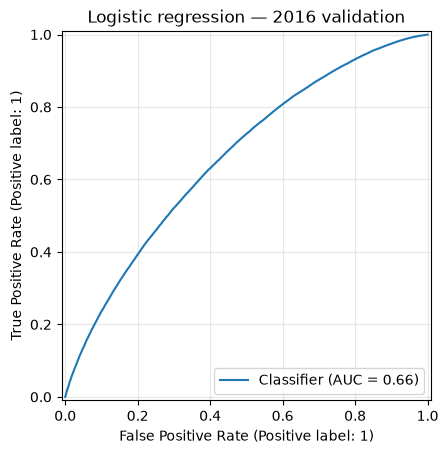

In [39]:
import matplotlib.pyplot as plt

from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_validation,
    p_validation,
)

plt.title("Logistic regression — 2016 validation")
plt.grid(alpha=0.3)
plt.show()

In [40]:
from sklearn.metrics import log_loss

train_default_rate = y_train.mean()
validation_default_rate = y_validation.mean()

p_constant = np.full(
    len(y_validation),
    train_default_rate,
)

baseline_log_loss = log_loss(
    y_validation,
    p_constant,
)

model_log_loss = log_loss(
    y_validation,
    p_validation,
)

print(f"Training default rate:   {train_default_rate:.4f}")
print(f"Validation default rate: {validation_default_rate:.4f}")
print(f"Constant baseline loss:  {baseline_log_loss:.4f}")
print(f"Logistic regression loss:{model_log_loss:.4f}")

Training default rate:   0.1846
Validation default rate: 0.2328
Constant baseline loss:  0.5499
Logistic regression loss:0.5206


In [41]:
oracle_constant_loss = log_loss(
    y_validation,
    np.full(len(y_validation), validation_default_rate),
)

print(f"Oracle constant loss: {oracle_constant_loss:.4f}")

Oracle constant loss: 0.5427


In [42]:
from sklearn.metrics import log_loss
import numpy as np
import pandas as pd

# Observed default rates
train_rate = y_train.mean()
validation_rate = y_validation.mean()

# Baseline 1: use the training default rate
p_baseline = np.full(
    len(y_validation),
    train_rate
)

# Baseline 2: use the validation default rate
p_oracle = np.full(
    len(y_validation),
    validation_rate
)

comparison = pd.DataFrame({
    "Log loss": {
        "Logistic regression": log_loss(
            y_validation, p_validation
        ),
        "Training-rate baseline": log_loss(
            y_validation, p_baseline
        ),
        "Oracle constant baseline": log_loss(
            y_validation, p_oracle
        ),
    }
})

print(f"Training default rate: {train_rate:.4f}")
print(f"Validation default rate: {validation_rate:.4f}")

display(comparison)

Training default rate: 0.1846
Validation default rate: 0.2328


,Log loss
Logistic regression,0.520641
Training-rate baseline,0.549939
Oracle constant baseline,0.542659


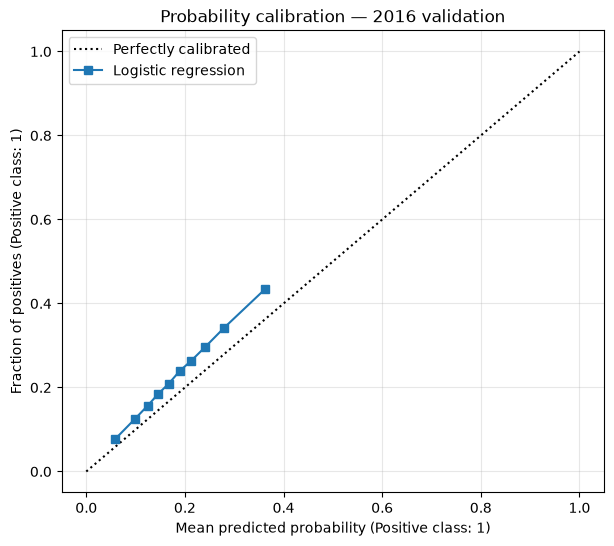

In [43]:
from sklearn.calibration import CalibrationDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 6))

CalibrationDisplay.from_predictions(
    y_validation,
    p_validation,
    n_bins=10,
    strategy="quantile",
    ax=ax,
    name="Logistic regression",
)

ax.set_title("Probability calibration — 2016 validation")
ax.grid(alpha=0.3)
ax.legend()

plt.show()

In [44]:
print(
    f"Mean predicted default probability: "
    f"{p_validation.mean():.4f}"
)

print(
    f"Observed default frequency: "
    f"{y_validation.mean():.4f}"
)

print(
    f"Difference (observed - predicted): "
    f"{y_validation.mean() - p_validation.mean():.4f}"
)

Mean predicted default probability: 0.1879
Observed default frequency: 0.2328
Difference (observed - predicted): 0.0449


In [45]:
from scipy.special import logit
from sklearn.linear_model import LogisticRegression

# Convert predicted probabilities to log-odds.
z_validation = logit(
    np.clip(p_validation, 1e-10, 1 - 1e-10)
)

# Fit a logistic calibration model.
calibration_model = LogisticRegression(
    C=np.inf,
    solver="lbfgs",
    max_iter=1000,
)

calibration_model.fit(
    z_validation.reshape(-1, 1),
    y_validation,
)

a = calibration_model.intercept_[0]
b = calibration_model.coef_[0, 0]

print(f"Calibration intercept: {a:.4f}")
print(f"Calibration slope:     {b:.4f}")

Calibration intercept: 0.2522
Calibration slope:     0.9752


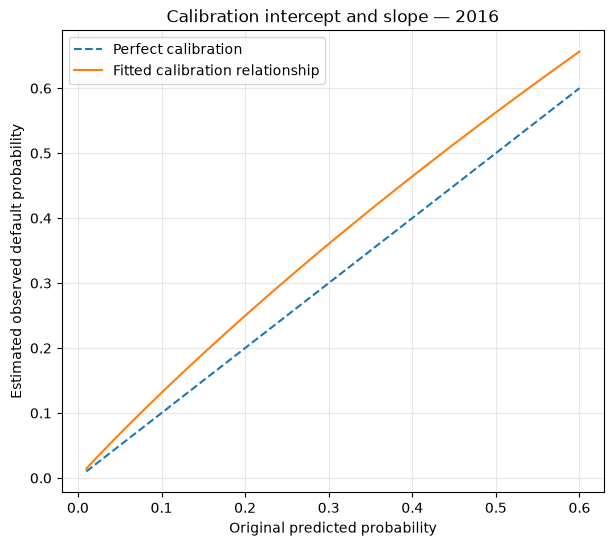

In [46]:
from scipy.special import expit

p_grid = np.linspace(0.01, 0.60, 300)

z_grid = logit(p_grid)

p_calibrated = expit(a + b * z_grid)

plt.figure(figsize=(7, 6))

plt.plot(
    p_grid,
    p_grid,
    "--",
    label="Perfect calibration",
)

plt.plot(
    p_grid,
    p_calibrated,
    label="Fitted calibration relationship",
)

plt.xlabel("Original predicted probability")
plt.ylabel("Estimated observed default probability")
plt.title("Calibration intercept and slope — 2016")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [47]:
from scipy.optimize import minimize_scalar
from scipy.special import expit

def intercept_loss(a0):
    probabilities = expit(z_validation + a0)
    return log_loss(y_validation, probabilities)

result = minimize_scalar(
    intercept_loss,
    method="bounded",
    bounds=(-5, 5),
)

a0 = result.x

print(f"Intercept-only correction: {a0:.4f}")
print(f"Full calibration intercept: {a:.4f}")
print(f"Full calibration slope:     {b:.4f}")

Intercept-only correction: 0.2866
Full calibration intercept: 0.2522
Full calibration slope:     0.9752


In [48]:
from scipy.special import expit

# Original predictions
p_original = p_validation

# Intercept-only correction
p_intercept = expit(z_validation + a0)

# Full calibration correction
p_full = expit(a + b * z_validation)

comparison = pd.DataFrame({
    "Original": evaluate_predictions(
        y_validation, p_original
    ),
    "Intercept only": evaluate_predictions(
        y_validation, p_intercept
    ),
    "Intercept + slope": evaluate_predictions(
        y_validation, p_full
    ),
})

display(comparison)

,Original,Intercept only,Intercept + slope
ROC-AUC,0.662143,0.662143,0.662143
Average precision,0.359399,0.359384,0.359384
Log loss,0.520641,0.513961,0.513945


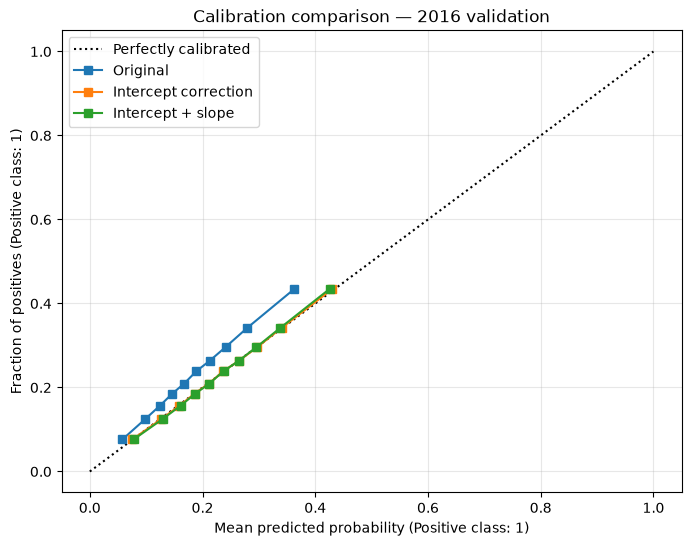

In [49]:
from sklearn.calibration import CalibrationDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6))

predictions = {
    "Original": p_original,
    "Intercept correction": p_intercept,
    "Intercept + slope": p_full,
}

for name, probabilities in predictions.items():
    CalibrationDisplay.from_predictions(
        y_validation,
        probabilities,
        n_bins=10,
        strategy="quantile",
        name=name,
        ax=ax,
    )

ax.set_title("Calibration comparison — 2016 validation")
ax.grid(alpha=0.3)
ax.legend()

plt.show()

In [50]:
# Extract 2017 predictors and outcomes
X_test = splits["test"][feature_columns].copy()
y_test = splits["test"]["Default"].copy()

# Apply the existing preprocessing pipeline
X_test_processed = preprocessor.transform(X_test)

# Obtain predictions from the original model
p_test = model.predict_proba(X_test_processed)[:, 1]

# Apply the corrections estimated using 2016 data
z_test = logit(np.clip(p_test, 1e-10, 1 - 1e-10))

p_test_intercept = expit(z_test + a0)
p_test_full = expit(a + b * z_test)

print("2017 observations:", len(y_test))
print("2017 default rate:", y_test.mean())

2017 observations: 169117
2017 default rate: 0.23127184138791487


In [51]:
test_comparison = pd.DataFrame({
    "Original": evaluate_predictions(
        y_test, p_test
    ),
    "Intercept correction": evaluate_predictions(
        y_test, p_test_intercept
    ),
    "Intercept + slope": evaluate_predictions(
        y_test, p_test_full
    ),
})

display(test_comparison)

,Original,Intercept correction,Intercept + slope
ROC-AUC,0.672870,0.67287,0.672870
Average precision,0.363977,0.36395,0.363950
Log loss,0.522330,0.51358,0.513406


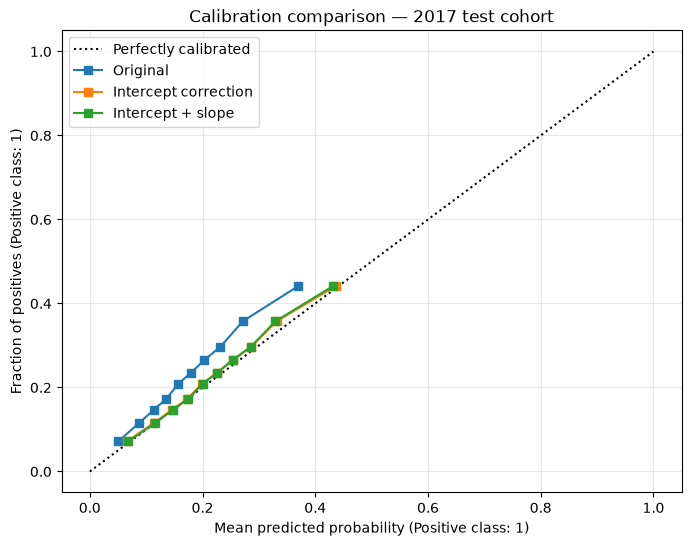

In [52]:
fig, ax = plt.subplots(figsize=(8, 6))

predictions_2017 = {
    "Original": p_test,
    "Intercept correction": p_test_intercept,
    "Intercept + slope": p_test_full,
}

for name, probabilities in predictions_2017.items():
    CalibrationDisplay.from_predictions(
        y_test,
        probabilities,
        n_bins=10,
        strategy="quantile",
        name=name,
        ax=ax,
    )

ax.set_title("Calibration comparison — 2017 test cohort")
ax.grid(alpha=0.3)
ax.legend()

plt.show()

In [53]:
print(f"Observed default rate: {y_test.mean():.4f}")
print(f"Original mean prediction: {p_test.mean():.4f}")
print(f"Intercept correction: {p_test_intercept.mean():.4f}")
print(f"Full correction: {p_test_full.mean():.4f}")

Observed default rate: 0.2313
Original mean prediction: 0.1800
Intercept correction: 0.2231
Full correction: 0.2233
